c:\Users\kmchw\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 28s 38ms/step - accuracy: 0.3086 - loss: 1.9038 - val_accuracy: 0.4940 - val_loss: 1.4322
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 33ms/step - accuracy: 0.5048 - loss: 1.3898 - val_accuracy: 0.5446 - val_loss: 1.3021
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 31ms/step - accuracy: 0.5603 - loss: 1.2490 - val_accuracy: 0.5745 - val_loss: 1.2220
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 31ms/step - accuracy: 0.5873 - loss: 1.1729 - val_accuracy: 0.5897 - val_loss: 1.1851
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6093 - loss: 1.1096 - val_accuracy: 0.6088 - val_loss: 1.1301
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.6355 - loss: 1.0453 - val_accuracy: 0.6160 - val_loss: 1.1061
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.6533 - loss: 0.9900 - val_accuracy: 0.6246 - val_loss: 1.0868
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 33ms/step - accuracy: 0.6706 - loss: 0.9350 - 

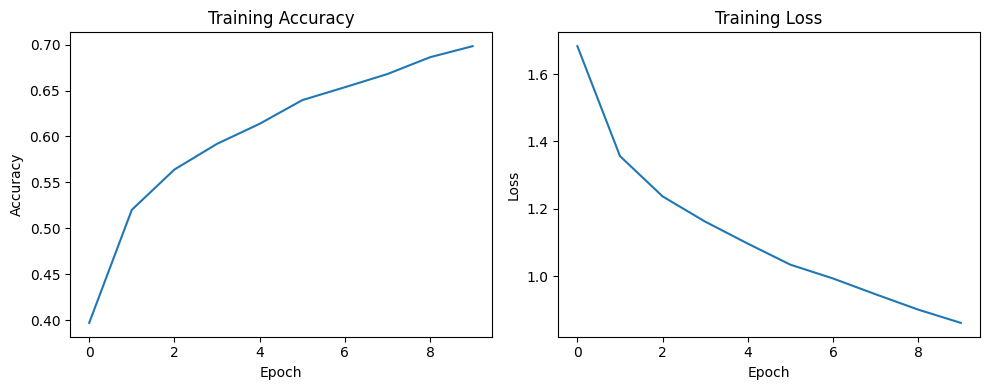

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

data = pd.read_csv("Datasets/FNN_CNN/CIFAR10/cifar-10.csv")

x = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

x = x.reshape(-1, 32, 32, 3)

x = x / 255.0

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# b. Define CNN architecture
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu',
                           input_shape=(32, 32, 3)),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# c. Train the model
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test, y_test)
)

# d. Estimate model performance
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Plot training accuracy and loss
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.tight_layout()
plt.show()

Epoch 1/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.3530 - loss: 1.7826 - val_accuracy: 0.5490 - val_loss: 1.2539
Epoch 2/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.5811 - loss: 1.2050 - val_accuracy: 0.6143 - val_loss: 1.1033
Epoch 3/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 18s 31ms/step - accuracy: 0.6482 - loss: 1.0076 - val_accuracy: 0.6465 - val_loss: 1.0053
Epoch 4/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 18s 31ms/step - accuracy: 0.6906 - loss: 0.8992 - val_accuracy: 0.6587 - val_loss: 0.9995
Epoch 5/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 21s 31ms/step - accuracy: 0.7173 - loss: 0.8199 - val_accuracy: 0.6630 - val_loss: 0.9670
Epoch 6/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 18s 31ms/step - accuracy: 0.7454 - loss: 0.7405 - val_accuracy: 0.6783 - val_loss: 0.9533
Epoch 7/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.7670 - loss: 0.6698 - val_accuracy: 0.6833 - val_loss: 0.9412
Epoch 8/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.7879 - loss: 0.6041 - 

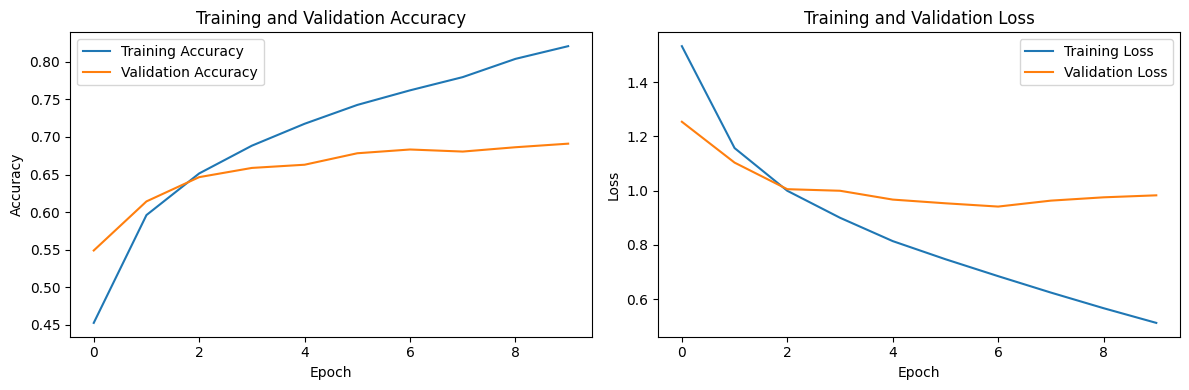

In [2]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

data = pd.read_csv("Datasets/FNN_CNN/CIFAR10/cifar-10.csv")

y = data.iloc[:, -1].values
x = data.iloc[:, :-1].values

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

x_train = x_train.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
x_test = x_test.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

loss, accuracy = model.evaluate(x_test, y_test)

print("Loss: ", loss * 100)
print("Accuracy: ", accuracy * 100)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()